In [1]:
import os
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import kagglehub
import numpy as np
import matplotlib.pyplot as plt

In [2]:
X = 5
while X>0 :
    X=X - 1
print (X)

0


In [3]:
import os

BASE_PATH = "/kaggle/input/datasets/humansintheloop/semantic-segmentation-of-aerial-imagery"

print("Contenu du dossier principal :")
print(os.listdir(BASE_PATH))

print("\nContenu du dossier 'Semantic segmentation dataset' :")
dataset_path = os.path.join(BASE_PATH, "Semantic segmentation dataset")
print(os.listdir(dataset_path))

# Afficher les 2 premiers tiles pour voir la structure interne
for tile in os.listdir(dataset_path)[:3]:
    tile_path = os.path.join(dataset_path, tile)
    if os.path.isdir(tile_path):
        print(f"\nTile : {tile}")
        print("  →", os.listdir(tile_path))

Contenu du dossier principal :
['Semantic segmentation dataset']

Contenu du dossier 'Semantic segmentation dataset' :
['Tile 7', 'Tile 8', 'Tile 2', 'Tile 5', 'Tile 1', 'Tile 3', 'classes.json', 'Tile 6', 'Tile 4']

Tile : Tile 7
  → ['images', 'masks']

Tile : Tile 8
  → ['images', 'masks']

Tile : Tile 2
  → ['images', 'masks']


In [4]:
import os
from tqdm import tqdm
import cv2
from sklearn.model_selection import train_test_split

PATCH_SIZE = 256

# Chemin exact sur Kaggle
BASE_PATH = "/kaggle/input/datasets/humansintheloop/semantic-segmentation-of-aerial-imagery"

# ====================== RECHERCHE ROBUSTE ======================
image_mask_pairs = []

print("Exploration de la structure de la dataset...\n")

for tile_folder in os.listdir(BASE_PATH):
    tile_path = os.path.join(BASE_PATH, tile_folder)
    
    # On cherche uniquement les dossiers "Tile X"
    if not os.path.isdir(tile_path) or not tile_folder.startswith("Tile"):
        continue
    
    images_dir = os.path.join(tile_path, "images")
    masks_dir  = os.path.join(tile_path, "masks")
    
    if not (os.path.exists(images_dir) and os.path.exists(masks_dir)):
        print(f"⚠️ Dossier manquant dans {tile_folder}")
        continue
    
    images = sorted([f for f in os.listdir(images_dir) 
                    if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
    
    print(f"→ {tile_folder} : {len(images)} images trouvées")
    
    for img_name in images:
        mask_path = os.path.join(masks_dir, img_name)
        img_path  = os.path.join(images_dir, img_name)
        
        if os.path.exists(mask_path):
            image_mask_pairs.append((img_path, mask_path, img_name))

print(f"\nTotal de paires trouvées : {len(image_mask_pairs)}")

Exploration de la structure de la dataset...


Total de paires trouvées : 0


In [5]:
import os
import json
from PIL import Image

# Chemins des dossiers et fichier JSON
json_path = '/kaggle/input/semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/classes.json'
images_dir = '/kaggle/input/datasets/humansintheloop/semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 1/images'
masks_dir = '/kaggle/input/datasets/humansintheloop/semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 1/masks'

# Paramètres
target_size = (192, 192)  # largeur, hauteur
images = []
masks = []

'''# Lire le fichier JSON
with open('/kaggle/input/semantic-segmentation-of-satellite-image/Semantic segmentation dataset/classes.json', 'r') as f:
    data = json.load(f)
print("Type de data :", type(data))

# Affiche juste les 200 premiers caractères
print("Contenu brut (début) :", str(data)[:200])'''

'# Lire le fichier JSON\nwith open(\'/kaggle/input/semantic-segmentation-of-satellite-image/Semantic segmentation dataset/classes.json\', \'r\') as f:\n    data = json.load(f)\nprint("Type de data :", type(data))\n\n# Affiche juste les 200 premiers caractères\nprint("Contenu brut (début) :", str(data)[:200])'

In [6]:
# Mapping couleur RGB → étiquette de classe
color_to_class = {
    (60, 16, 152): 0,   # Building - #3C1098
    (132, 41, 246): 1,  # Land - #8429F6
    (110, 193, 228): 2, # Road - #6EC1E4
    (254, 221, 58): 3,  # Vegetation - #FEDD3A
    (226, 169, 41): 4,  # Water - #E2A929
    (0, 0, 0): 5  # Unlabeled - #9B9B9B
}
import numpy as np
from PIL import Image

# Charger le masque
mask = Image.open("/kaggle/input/datasets/humansintheloop/semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 1/masks/image_part_001.png").convert("RGB")
mask_np = np.array(mask)

# Créer un masque vide pour stocker les classes
label_mask = np.zeros(mask_np.shape[:2], dtype=np.uint8)

# Appliquer le mapping couleur → classe
for color, class_idx in color_to_class.items():
    matches = np.all(mask_np == color, axis=-1)
    label_mask[matches] = class_idx

# Vérification : Afficher les classes uniques
print("Valeurs de classes uniques dans le masque :", np.unique(label_mask))


Valeurs de classes uniques dans le masque : [0 1 2 3 4]


In [7]:
print(label_mask.shape)

(644, 797)


In [8]:
import os
import numpy as np
from PIL import Image

# Dossier de base (à adapter selon votre environnement)
base_path = '/kaggle/input/datasets/humansintheloop/semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset'

# Mapping RGB → classe
color_to_class = {
    (60, 16, 152): 0,   # Building
    (132, 41, 246): 1,  # Land (unpaved)
    (110, 193, 228): 2, # Road
    (254, 221, 58): 3,  # Vegetation
    (226, 169, 41): 4,  # Water
    (0, 0, 0): 5  # Unlabeled
}

# Taille cible
target_size = (256, 256)

# Liste pour stocker tous les masques convertis
all_masks = []

# Parcourir les 8 Tiles
for tile_id in range(1, 9):
    mask_dir = os.path.join(base_path, f'Tile {tile_id}', 'masks')
    
    for filename in sorted(os.listdir(mask_dir)):
        if filename.endswith('.png'):
            mask_path = os.path.join(mask_dir, filename)
            
            # Lire et convertir en RGB
            mask_rgb = Image.open(mask_path).convert('RGB')
            mask_array = np.array(mask_rgb)
            
            # Créer une image de labels initialisée à zéro
            label_mask = np.zeros(mask_array.shape[:2], dtype=np.uint8)
            
            # Appliquer le mapping couleur → classe
            for color, class_id in color_to_class.items():
                matches = np.all(mask_array == color, axis=-1)
                label_mask[matches] = class_id

            # Redimensionner le masque encodé (après mapping)
            resized_mask = Image.fromarray(label_mask).resize(target_size, resample=Image.NEAREST)
            all_masks.append(np.array(resized_mask))

            # Vérifier les classes présentes
            print(f"{filename} (Tile {tile_id}): classes trouvées -> {np.unique(resized_mask)}")


image_part_001.png (Tile 1): classes trouvées -> [0 1 2 3 4]
image_part_002.png (Tile 1): classes trouvées -> [0 1 2 4]
image_part_003.png (Tile 1): classes trouvées -> [0 1 2 3 4]
image_part_004.png (Tile 1): classes trouvées -> [0 1 2 4]
image_part_005.png (Tile 1): classes trouvées -> [0 1 2 4]
image_part_006.png (Tile 1): classes trouvées -> [0 1 2 3 4]
image_part_007.png (Tile 1): classes trouvées -> [0 1 2 3 4]
image_part_008.png (Tile 1): classes trouvées -> [0 1 2 3 4]
image_part_009.png (Tile 1): classes trouvées -> [0 1 2 3 4]
image_part_001.png (Tile 2): classes trouvées -> [0 1 2]
image_part_002.png (Tile 2): classes trouvées -> [0 1 2]
image_part_003.png (Tile 2): classes trouvées -> [0 1 2 3]
image_part_004.png (Tile 2): classes trouvées -> [0 1 2 3 4]
image_part_005.png (Tile 2): classes trouvées -> [0 1 2 3 4]
image_part_006.png (Tile 2): classes trouvées -> [0 1 2 3 4]
image_part_007.png (Tile 2): classes trouvées -> [0 1 2 3 4]
image_part_008.png (Tile 2): classes tro

In [9]:
import os
from PIL import Image

base_dir = '/kaggle/input/datasets/humansintheloop/semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset'  # racine de ton dataset
titles = ['Tile 1', 'Tile 2','Tile 3','Tile 4','Tile 5','Tile 6','Tile 7','Tile 8']
target_size = (256, 256)

images = []
#masks = []

for title in titles:
    images_dir = os.path.join(base_dir, title, 'images')
    #masks_dir = os.path.join(base_dir, title, 'masks')

    image_filenames = sorted([f for f in os.listdir(images_dir) if f.endswith('.jpg')])

    for img_filename in image_filenames:
        image_path = os.path.join(images_dir, img_filename)
        #mask_filename = os.path.splitext(img_filename)[0] + '.png'
        #mask_path = os.path.join(masks_dir, mask_filename)

        if os.path.exists(mask_path):
            image = Image.open(image_path).convert("RGB").resize(target_size)
            #mask = Image.open(mask_path).convert("L").resize(target_size)
            images.append(image)
            #masks.append(mask)
        else:
            print(f"Pas de masque pour : {img_filename} dans {title}/")

print(f"Total : {len(images)} paires image-masque chargées à partir de {len(titles)} dossiers.")

Total : 72 paires image-masque chargées à partir de 8 dossiers.


In [10]:
print(len(images))
print(len(all_masks))
print(np.unique(all_masks))

72
72
[0 1 2 3 4 5]


Nombre d'images : 72
Nombre de masques : 72


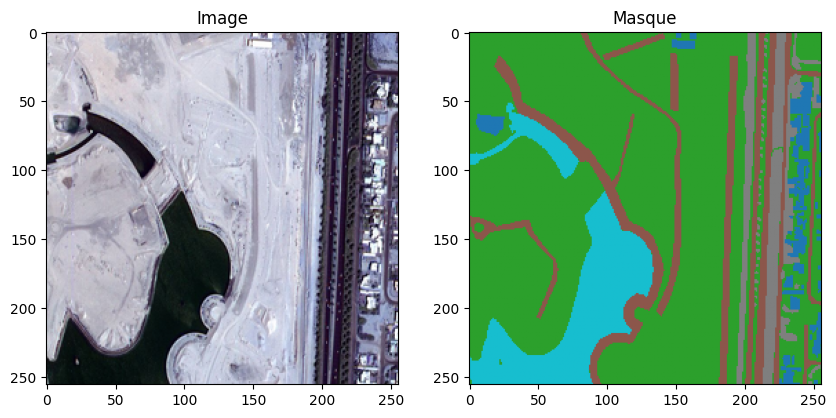

In [11]:
import matplotlib.pyplot as plt

# Affichage des longueurs pour vérification
print("Nombre d'images :", len(images))
print("Nombre de masques :", len(all_masks))

# Vérification visuelle du premier élément (image + masque)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Image d'entrée (si c'est un objet PIL)
if isinstance(images[2], Image.Image):
    axes[0].imshow(images[2])
else:
    axes[0].imshow(np.array(images[2]))
axes[0].set_title("Image")

# Masque (encoded ou RGB selon le traitement précédent)
axes[1].imshow(all_masks[2], cmap='tab10')  # 'tab10' pour visualiser des classes
axes[1].set_title("Masque")
plt.show()

In [12]:
import numpy as np
images_array = np.array(images)
masks_array = np.array(all_masks)
print("Shape des images:", images_array.shape)
print("Shape des masques:", masks_array.shape)

Shape des images: (72, 256, 256, 3)
Shape des masques: (72, 256, 256)


In [13]:
# One-hot encoding avec 6 classes
masks_onehot = np.eye(6)[masks_array]
# Afficher la forme du tableau one-hot
print("Shape des images:", images_array.shape)  # Les images devraient être de forme (72, 192, 192, 3)
print("Shape des masques après one-hot encoding:", masks_onehot.shape)  # Les masques devraient être de forme (72, 192, 192, 6) 

Shape des images: (72, 256, 256, 3)
Shape des masques après one-hot encoding: (72, 256, 256, 6)


In [14]:
from sklearn.model_selection import train_test_split
# Diviser les données en train et validation
X_train, X_val, y_train, y_val = train_test_split(images_array, masks_onehot, test_size=0.2, random_state=42)

# Vérification des formes après la division
print("Shape des images d'entraînement:", X_train.shape)
print("Shape des images de validation:", X_val.shape)
print("Shape des masques d'entraînement:", y_train.shape)
print("Shape des masques de validation:", y_val.shape)

Shape des images d'entraînement: (57, 256, 256, 3)
Shape des images de validation: (15, 256, 256, 3)
Shape des masques d'entraînement: (57, 256, 256, 6)
Shape des masques de validation: (15, 256, 256, 6)


In [15]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import backend as K

# =========================================================
# CONFIGURATION
# =========================================================

IMG_SIZE = 256
NUM_CLASSES = 6

# =========================================================
# DICE LOSS
# =========================================================

def dice_loss(y_true, y_pred, smooth=1e-6):

    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    intersection = tf.reduce_sum(y_true_f * y_pred_f)

    return 1 - ((2. * intersection + smooth) /
                (tf.reduce_sum(y_true_f) +
                 tf.reduce_sum(y_pred_f) + smooth))


def total_loss(y_true, y_pred):

    cce = tf.keras.losses.CategoricalCrossentropy()(y_true, y_pred)

    return 0.5 * cce + 0.5 * dice_loss(y_true, y_pred)

# =========================================================
# CONV BLOCK
# =========================================================

def conv_block(x, filters):

    x = layers.Conv2D(filters, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    x = layers.Conv2D(filters, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    return x

# =========================================================
# ASPP BLOCK (DeepLabV3+)
# =========================================================



2026-05-20 13:44:45.206927: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1779284685.781668     112 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1779284685.914271     112 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1779284687.059444     112 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779284687.059488     112 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779284687.059491     112 computation_placer.cc:177] computation placer alr

In [16]:
def ASPP(inputs):

    shape = inputs.shape

    y1 = layers.Conv2D(256, 1, dilation_rate=1,
                       padding="same", use_bias=False)(inputs)
    y1 = layers.BatchNormalization()(y1)
    y1 = layers.Activation("relu")(y1)

    y2 = layers.Conv2D(256, 3, dilation_rate=6,
                       padding="same", use_bias=False)(inputs)
    y2 = layers.BatchNormalization()(y2)
    y2 = layers.Activation("relu")(y2)

    y3 = layers.Conv2D(256, 3, dilation_rate=12,
                       padding="same", use_bias=False)(inputs)
    y3 = layers.BatchNormalization()(y3)
    y3 = layers.Activation("relu")(y3)

    y4 = layers.Conv2D(256, 3, dilation_rate=18,
                       padding="same", use_bias=False)(inputs)
    y4 = layers.BatchNormalization()(y4)
    y4 = layers.Activation("relu")(y4)

    y = layers.Concatenate()([y1, y2, y3, y4])

    y = layers.Conv2D(256, 1, padding="same",
                      use_bias=False)(y)

    y = layers.BatchNormalization()(y)
    y = layers.Activation("relu")(y)

    return y

In [17]:
def build_unet():

    inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3))

    encoder = EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_tensor=inputs
    )

    # Skip connections
    s1 = encoder.get_layer("stem_activation").output
    s2 = encoder.get_layer("block2a_expand_activation").output
    s3 = encoder.get_layer("block3a_expand_activation").output
    s4 = encoder.get_layer("block4a_expand_activation").output

    bridge = encoder.get_layer("top_activation").output

    # =====================================================
    # Decoder 1
    # =====================================================

    d1 = layers.Conv2DTranspose(
        512, 2, strides=2, padding='same'
    )(bridge)

    s4 = layers.Resizing(
        d1.shape[1],
        d1.shape[2]
    )(s4)

    d1 = layers.Concatenate()([d1, s4])

    d1 = conv_block(d1, 512)

    # =====================================================
    # Decoder 2
    # =====================================================

    d2 = layers.Conv2DTranspose(
        256, 2, strides=2, padding='same'
    )(d1)

    s3 = layers.Resizing(
        d2.shape[1],
        d2.shape[2]
    )(s3)

    d2 = layers.Concatenate()([d2, s3])

    d2 = conv_block(d2, 256)

    # =====================================================
    # Decoder 3
    # =====================================================

    d3 = layers.Conv2DTranspose(
        128, 2, strides=2, padding='same'
    )(d2)

    s2 = layers.Resizing(
        d3.shape[1],
        d3.shape[2]
    )(s2)

    d3 = layers.Concatenate()([d3, s2])

    d3 = conv_block(d3, 128)

    # =====================================================
    # Decoder 4
    # =====================================================

    d4 = layers.Conv2DTranspose(
        64, 2, strides=2, padding='same'
    )(d3)

    s1 = layers.Resizing(
        d4.shape[1],
        d4.shape[2]
    )(s1)

    d4 = layers.Concatenate()([d4, s1])

    d4 = conv_block(d4, 64)

    # =====================================================
    # Final Upsampling
    # =====================================================

    outputs = layers.Conv2D(
        NUM_CLASSES,
        1,
        padding='same',
        activation='softmax'
    )(d4)

    outputs = layers.Resizing(
        IMG_SIZE,
        IMG_SIZE
    )(outputs)

    return Model(inputs, outputs, name="UNet")

In [18]:
def build_deeplabv3plus(IMG_SIZE=256, NUM_CLASSES=6):
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    
    encoder = EfficientNetB0(include_top=False, 
                             weights='imagenet', 
                             input_tensor=inputs)
    
    # Low-level features
    low_level = encoder.get_layer("block2a_expand_activation").output   # 128x128
    
    # Deep features
    x = encoder.get_layer("top_activation").output                     # ~8x8
    
    x = ASPP(x)
    
    # Upsampling dynamique pour matcher low-level
    low_h, low_w = low_level.shape[1], low_level.shape[2]
    deep_h, deep_w = x.shape[1], x.shape[2]
    
    up_factor_h = low_h // deep_h
    up_factor_w = low_w // deep_w
    
    x = layers.UpSampling2D(size=(up_factor_h, up_factor_w), 
                            interpolation='bilinear')(x)
    
    # Préparer low-level
    low_level = layers.Conv2D(48, 1, padding='same', use_bias=False)(low_level)
    low_level = layers.BatchNormalization()(low_level)
    low_level = layers.Activation('relu')(low_level)
    
    # Concatenation
    x = layers.Concatenate()([x, low_level])
    
    # Refinement
    x = conv_block(x, 256)
    x = conv_block(x, 256)
    
    # ==================== UPSAMPLING FINAL CORRIGÉ ====================
    x = layers.UpSampling2D(size=(2, 2), interpolation='bilinear')(x)  # 128x128 → 256x256
    
    # Output
    outputs = layers.Conv2D(NUM_CLASSES, 1, padding='same', activation='softmax')(x)
    
    model = tf.keras.Model(inputs, outputs, name="DeepLabV3Plus_256")
    return model

In [19]:
# =========================================================
# SEGNET
# =========================================================

def build_segnet(IMG_SIZE=256, NUM_CLASSES=6):

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    # =====================================================
    # Encoder : EfficientNetB0
    # =====================================================

    encoder = EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_tensor=inputs
    )

    s1 = encoder.get_layer("stem_activation").output
    s2 = encoder.get_layer("block2a_expand_activation").output
    s3 = encoder.get_layer("block3a_expand_activation").output
    s4 = encoder.get_layer("block4a_expand_activation").output

    bridge = encoder.get_layer("top_activation").output

    # =====================================================
    # Decoder
    # =====================================================

    x = layers.UpSampling2D(size=(2,2))(bridge)

    s4 = layers.Resizing(x.shape[1], x.shape[2])(s4)

    x = layers.Concatenate()([x, s4])

    x = conv_block(x, 512)

    # -----------------------------------------------------

    x = layers.UpSampling2D(size=(2,2))(x)

    s3 = layers.Resizing(x.shape[1], x.shape[2])(s3)

    x = layers.Concatenate()([x, s3])

    x = conv_block(x, 256)

    # -----------------------------------------------------

    x = layers.UpSampling2D(size=(2,2))(x)

    s2 = layers.Resizing(x.shape[1], x.shape[2])(s2)

    x = layers.Concatenate()([x, s2])

    x = conv_block(x, 128)

    # -----------------------------------------------------

    x = layers.UpSampling2D(size=(2,2))(x)

    s1 = layers.Resizing(x.shape[1], x.shape[2])(s1)

    x = layers.Concatenate()([x, s1])

    x = conv_block(x, 64)

    # =====================================================
    # Final Output
    # =====================================================

    outputs = layers.Conv2D(
        NUM_CLASSES,
        1,
        activation='softmax',
        padding='same'
    )(x)

    outputs = layers.Resizing(
        IMG_SIZE,
        IMG_SIZE
    )(outputs)

    model = Model(inputs, outputs, name="SegNet")

    return model

In [20]:
# =========================================================
# W-NET
# =========================================================

def build_wnet(IMG_SIZE=256, NUM_CLASSES=6):

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    # =====================================================
    # PREMIER U-NET
    # =====================================================

    encoder1 = EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_tensor=inputs
    )

    s1 = encoder1.get_layer("stem_activation").output
    s2 = encoder1.get_layer("block2a_expand_activation").output
    s3 = encoder1.get_layer("block3a_expand_activation").output
    s4 = encoder1.get_layer("block4a_expand_activation").output

    bridge = encoder1.get_layer("top_activation").output

    # ================= Decoder 1 =================

    d1 = layers.Conv2DTranspose(
        512, 2, strides=2, padding='same'
    )(bridge)

    s4_r = layers.Resizing(
        d1.shape[1],
        d1.shape[2]
    )(s4)

    d1 = layers.Concatenate()([d1, s4_r])

    d1 = conv_block(d1, 512)

    # -------------------------------------------------

    d2 = layers.Conv2DTranspose(
        256, 2, strides=2, padding='same'
    )(d1)

    s3_r = layers.Resizing(
        d2.shape[1],
        d2.shape[2]
    )(s3)

    d2 = layers.Concatenate()([d2, s3_r])

    d2 = conv_block(d2, 256)

    # -------------------------------------------------

    d3 = layers.Conv2DTranspose(
        128, 2, strides=2, padding='same'
    )(d2)

    s2_r = layers.Resizing(
        d3.shape[1],
        d3.shape[2]
    )(s2)

    d3 = layers.Concatenate()([d3, s2_r])

    d3 = conv_block(d3, 128)

    # -------------------------------------------------

    d4 = layers.Conv2DTranspose(
        64, 2, strides=2, padding='same'
    )(d3)

    s1_r = layers.Resizing(
        d4.shape[1],
        d4.shape[2]
    )(s1)

    d4 = layers.Concatenate()([d4, s1_r])

    d4 = conv_block(d4, 64)

    # =====================================================
    # INTERMEDIATE SEGMENTATION
    # =====================================================

    inter_output = layers.Conv2D(
        NUM_CLASSES,
        1,
        activation='softmax',
        padding='same'
    )(d4)

    inter_output = layers.Resizing(
        IMG_SIZE,
        IMG_SIZE
    )(inter_output)

    # =====================================================
    # SECOND U-NET
    # =====================================================

    x = conv_block(inter_output, 64)

    x = layers.MaxPooling2D()(x)

    x = conv_block(x, 128)

    x = layers.MaxPooling2D()(x)

    x = conv_block(x, 256)

    # ================= Decoder 2 =================

    x = layers.UpSampling2D(size=(2,2))(x)

    x = conv_block(x, 128)

    x = layers.UpSampling2D(size=(2,2))(x)

    x = conv_block(x, 64)

    # =====================================================
    # FINAL OUTPUT
    # =====================================================

    outputs = layers.Conv2D(
        NUM_CLASSES,
        1,
        activation='softmax',
        padding='same'
    )(x)

    outputs = layers.Resizing(
        IMG_SIZE,
        IMG_SIZE
    )(outputs)

    model = Model(inputs, outputs, name="WNet")

    return model

In [21]:
from tensorflow.keras import layers
import tensorflow as tf

# =========================================================
# SPATIAL ATTENTION (version Keras compatible)
# =========================================================
def spatial_attention(x):
    # Average pooling et Max pooling sur les canaux
    avg_pool = layers.Lambda(lambda z: tf.reduce_mean(z, axis=-1, keepdims=True))(x)
    max_pool = layers.Lambda(lambda z: tf.reduce_max(z, axis=-1, keepdims=True))(x)
    
    # Concaténer les deux
    concat = layers.Concatenate(axis=-1)([avg_pool, max_pool])
    
    # Convolution 7x7 pour générer la carte d'attention
    attention = layers.Conv2D(1, 7, padding='same', activation='sigmoid')(concat)
    
    return layers.Multiply()([x, attention])


# =========================================================
# CHANNEL ATTENTION (version Keras compatible)
# =========================================================
def channel_attention(x, ratio=8):
    channel = x.shape[-1]
    
    # Global Average Pooling
    avg_pool = layers.GlobalAveragePooling2D()(x)
    avg_pool = layers.Reshape((1, 1, channel))(avg_pool)
    
    # MLP
    dense1 = layers.Dense(channel // ratio, activation='relu')(avg_pool)
    dense2 = layers.Dense(channel, activation='sigmoid')(dense1)
    
    return layers.Multiply()([x, dense2])


# =========================================================
# META LEARNER (corrigé)
# =========================================================
def build_meta_learner(IMG_SIZE=256, NUM_CLASSES=6):
    inputs = layers.Input((IMG_SIZE, IMG_SIZE, NUM_CLASSES * 4))
    
    x = conv_block(inputs, 128)
    
    x = spatial_attention(x)
    x = channel_attention(x)
    
    x = conv_block(x, 128)
    x = layers.Conv2D(64, 3, padding='same', activation='relu')(x)
    
    outputs = layers.Conv2D(NUM_CLASSES, 1, padding='same', activation='softmax')(x)
    
    model = tf.keras.Model(inputs, outputs, name="Attention_MetaLearner")
    return model

In [22]:
unet_model = build_unet()

I0000 00:00:1779284721.781728     112 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1779284721.788101     112 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [23]:
deeplab_model = build_deeplabv3plus()

In [24]:
segnet_model = build_segnet()


In [25]:
wnet_model = build_wnet()

In [26]:

meta_model = build_meta_learner()

In [27]:
# =========================================================
# DICE SCORE (Multi-class)
# =========================================================
def dice_score(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    
    # Flatten
    y_true_f = tf.reshape(y_true, [-1, tf.shape(y_true)[-1]])
    y_pred_f = tf.reshape(y_pred, [-1, tf.shape(y_pred)[-1]])
    
    intersection = tf.reduce_sum(y_true_f * y_pred_f, axis=0)
    union = tf.reduce_sum(y_true_f, axis=0) + tf.reduce_sum(y_pred_f, axis=0)
    
    dice = tf.reduce_mean((2. * intersection + smooth) / (union + smooth))
    return dice

In [28]:
# =========================================================
# COMPILE
# =========================================================

unet_model.compile(
    optimizer='adam',
    loss=total_loss,
    metrics=['accuracy', dice_score,total_loss]
)

deeplab_model.compile(
    optimizer='adam',
    loss=total_loss,
    metrics=['accuracy', dice_score,total_loss]
)


In [39]:
segnet_model.compile(
    optimizer='adam',
    loss=total_loss,
    metrics=['accuracy', dice_score,total_loss]
)

wnet_model.compile(
    optimizer='adam',
    loss=total_loss,
    metrics=['accuracy', dice_score,total_loss]
)

In [29]:
meta_model.compile(
    optimizer='adam',
    loss=total_loss,
    metrics=['accuracy', dice_score,total_loss]
)

In [30]:
# =========================================================
# SUMMARY
# =========================================================

print("\n========== U-NET ==========\n")
unet_model.summary()

print("\n========== DEEPLABV3+ ==========\n")
deeplab_model.summary()

print("\n========== U-NET ==========\n")
unet_model.summary()

print("\n========== DEEPLABV3+ ==========\n")
deeplab_model.summary()

print("\n========== META LEARNER ==========\n")
meta_model.summary()


========== U-NET ==========



Model: "UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 256, 256,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 256, 256,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 256, 256,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 257, 257,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 128, 128,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 128, 128,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 128, 128,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 128, 128,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 128, 128,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 128, 128,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 128, 128,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 128, 128,  │        512 │ block1a_se_excit

 Total params: 15,203,689 (58.00 MB)

 Trainable params: 15,157,826 (57.82 MB)

 Non-trainable params: 45,863 (179.16 KB)


========== DEEPLABV3+ ==========



Model: "DeepLabV3Plus_256"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_2         │ (None, 256, 256,  │          0 │ input_layer_1[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_1     │ (None, 256, 256,  │          7 │ rescaling_2[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_3         │ (None, 256, 256,  │          0 │ normalization_1[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 257, 257,  │          0 │ rescaling_3[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 128, 128,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 128, 128,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 128, 128,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 128, 128,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 128, 128,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 128, 128,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 128, 128,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 128, 128,  │        512 │ block1a_se_excit

 Total params: 15,973,225 (60.93 MB)

 Trainable params: 15,926,498 (60.75 MB)

 Non-trainable params: 46,727 (182.53 KB)


========== U-NET ==========



Model: "UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 256, 256,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 256, 256,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 256, 256,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 257, 257,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 128, 128,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 128, 128,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 128, 128,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 128, 128,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 128, 128,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 128, 128,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 128, 128,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 128, 128,  │        512 │ block1a_se_excit

 Total params: 15,203,689 (58.00 MB)

 Trainable params: 15,157,826 (57.82 MB)

 Non-trainable params: 45,863 (179.16 KB)


========== DEEPLABV3+ ==========



Model: "DeepLabV3Plus_256"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_2         │ (None, 256, 256,  │          0 │ input_layer_1[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_1     │ (None, 256, 256,  │          7 │ rescaling_2[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_3         │ (None, 256, 256,  │          0 │ normalization_1[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 257, 257,  │          0 │ rescaling_3[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 128, 128,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 128, 128,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 128, 128,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 128, 128,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 128, 128,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 128, 128,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 128, 128,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 128, 128,  │        512 │ block1a_se_excit

 Total params: 15,973,225 (60.93 MB)

 Trainable params: 15,926,498 (60.75 MB)

 Non-trainable params: 46,727 (182.53 KB)


========== META LEARNER ==========



Model: "Attention_MetaLearner"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_49 (Conv2D)  │ (None, 256, 256,  │     27,776 │ input_layer_4[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        512 │ conv2d_49[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_44       │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_50 (Conv2D)  │ (None, 256, 256,  │    147,584 │ activation_44[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        512 │ conv2d_50[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_45       │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 256, 256,  │          0 │ activation_45[0]… │
│                     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_1 (Lambda)   │ (None, 256, 256,  │          0 │ activation_45[0]… │
│                     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_14      │ (None, 256, 256,  │          0 │ lambda[0][0],     │
│ (Concatenate)       │ 2)                │            │ lambda_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_51 (Conv2D)  │ (None, 256, 256,  │         99 │ concatenate_14[0… │
│                     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 256, 256,  │          0 │ activation_45[0]… │
│                     │ 128)              │            │ conv2d_51[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ multiply[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 128) │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1, 1, 16)  │      2,064 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1, 1, 128) │      2,176 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_1          │ (None, 256, 256,  │          0 │ multiply[0][0],   │
│ (Multiply)          │ 128)              │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_52 (Conv2D)  │ (None, 256, 256,  │    147,584 │ multiply_1[0][0]

 Total params: 551,097 (2.10 MB)

 Trainable params: 550,073 (2.10 MB)

 Non-trainable params: 1,024 (4.00 KB)

In [31]:
segnet_model = build_segnet()

wnet_model = build_wnet()

In [32]:
import tensorflow as tf
from tensorflow.keras import layers, Model

# =========================================================
# 1. CONSTRUCTION DU MODÈLE DE STACKING
# =========================================================
def build_stacking_ensemble(unet_model, deeplab_model,segnet_model,wnet_model, meta_model, 
                           IMG_SIZE=256, NUM_CLASSES=6):
    
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="input_image")
    
    # Prédictions des deux modèles de base
    unet_pred = unet_model(inputs)          # (None, 256, 256, 6)
    deeplab_pred = deeplab_model(inputs)    # (None, 256, 256, 6)
    segnet_pred = segnet_model(inputs)
    wnet_pred = wnet_model(inputs)
    
    # Stacking des prédictions (concaténation sur l'axe des canaux)
    stacked_preds = layers.Concatenate(axis=-1, name="stacked_features")(
        [unet_pred, deeplab_pred, segnet_pred, wnet_pred]
    )  # Shape: (None, 256, 256, 24)
    
    # Passage au Meta Learner
    final_output = meta_model(stacked_preds)
    
    # Modèle final
    ensemble_model = Model(inputs=inputs, 
                          outputs=final_output, 
                          name="Stacking_Ensemble")
    
    return ensemble_model


In [33]:
# =========================================================
# 2. CRÉATION ET COMPILATION
# =========================================================
ensemble_model = build_stacking_ensemble(
    unet_model=unet_model,
    deeplab_model=deeplab_model,
    segnet_model= segnet_model,
    wnet_model=wnet_model,
    meta_model=meta_model,
    IMG_SIZE=256,
    NUM_CLASSES=6
)


In [34]:
# Compilation
ensemble_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=total_loss,
    metrics=[
        'accuracy',
        tf.keras.metrics.MeanIoU(num_classes=6, name="mIoU"), dice_score,total_loss
    ]
)

ensemble_model.summary()

Model: "Stacking_Ensemble"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ UNet (Functional)   │ (None, 256, 256,  │ 15,203,689 │ input_image[0][0] │
│                     │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ DeepLabV3Plus_256   │ (None, 256, 256,  │ 15,973,225 │ input_image[0][0] │
│ (Functional)        │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SegNet (Functional) │ (None, 256, 256,  │ 16,206,249 │ input_image[0][0] │
│                     │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ WNet (Functional)   │ (None, 256, 256,  │ 16,909,679 │ input_image[0][0] │
│                     │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stacked_features    │ (None, 256, 256,  │          0 │ UNet[0][0],       │
│ (Concatenate)       │ 24)               │            │ DeepLabV3Plus_25… │
│                     │                   │            │ SegNet[0][0],     │
│                     │                   │            │ WNet[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Attention_MetaLear… │ (None, 256, 256,  │    551,097 │ stacked_features… │
│ (Functional)        │ 6)                │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 64,843,939 (247.36 MB)

 Trainable params: 64,656,039 (246.64 MB)

 Non-trainable params: 187,900 (734.00 KB)

In [35]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

callbacks = [
    EarlyStopping(monitor='val_dice_score', 
                  patience=12, 
                  mode='max', 
                  restore_best_weights=True,
                  verbose=1),
    
    ReduceLROnPlateau(monitor='val_dice_score',
                      factor=0.5,
                      patience=5,
                      mode='max',
                      min_lr=1e-6,
                      verbose=1),
    
    ModelCheckpoint('best_unet.h5',          # change le nom selon le modèle
                    monitor='val_dice_score',
                    mode='max',
                    save_best_only=True,
                    verbose=1)
]

In [36]:
# =========================================================
# ENTRAÎNEMENT U-NET
# =========================================================
print("=== Entraînement U-Net ===")
history_unet = unet_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=4,
    callbacks=callbacks,
    verbose=1
)

=== Entraînement U-Net ===
Epoch 1/100


I0000 00:00:1779284820.557587     181 service.cc:152] XLA service 0x7a7be802c720 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1779284820.557646     181 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1779284820.557652     181 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1779284827.773390     181 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-05-20 13:47:17.820813: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 13:47:17.954576: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 13:47:18.268032: E external/local_xl

14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.3851 - dice_score: 0.2150 - loss: 1.1479 - total_loss: 1.1479

2026-05-20 13:48:21.500225: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 13:48:21.634601: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 13:48:21.768916: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 13:48:22.573564: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 13:48:22.707922: E external/local_xla/xla/stream_

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.3967 - dice_score: 0.2194 - loss: 1.1331 - total_loss: 1.1323  

2026-05-20 13:49:12.319717: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 13:49:12.454230: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 13:49:12.765172: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 13:49:12.906182: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 13:49:13.693113: E external/local_xla/xla/stream_


Epoch 1: val_dice_score improved from -inf to 0.07791, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 182s 6s/step - accuracy: 0.4069 - dice_score: 0.2233 - loss: 1.1202 - total_loss: 1.1187 - val_accuracy: 0.1684 - val_dice_score: 0.0779 - val_loss: 3.5292 - val_total_loss: 3.5282 - learning_rate: 0.0010
Epoch 2/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.7021 - dice_score: 0.3610 - loss: 0.6755 - total_loss: 0.6755
Epoch 2: val_dice_score improved from 0.07791 to 0.15094, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 187ms/step - accuracy: 0.7010 - dice_score: 0.3608 - loss: 0.6738 - total_loss: 0.6749 - val_accuracy: 0.2359 - val_dice_score: 0.1509 - val_loss: 2.7349 - val_total_loss: 2.7091 - learning_rate: 0.0010
Epoch 3/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.7150 - dice_score: 0.3909 - loss: 0.6037 - total_loss: 0.6037
Epoch 3: val_dice_score improved from 0.15094 to 0.21646, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 183ms/step - accuracy: 0.7158 - dice_score: 0.3915 - loss: 0.6020 - total_loss: 0.6008 - val_accuracy: 0.3232 - val_dice_score: 0.2165 - val_loss: 2.6149 - val_total_loss: 2.6078 - learning_rate: 0.0010
Epoch 4/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.7318 - dice_score: 0.4110 - loss: 0.5428 - total_loss: 0.5428
Epoch 4: val_dice_score improved from 0.21646 to 0.31941, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 179ms/step - accuracy: 0.7316 - dice_score: 0.4099 - loss: 0.5445 - total_loss: 0.5477 - val_accuracy: 0.4314 - val_dice_score: 0.3194 - val_loss: 1.3052 - val_total_loss: 1.3200 - learning_rate: 0.0010
Epoch 5/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.7414 - dice_score: 0.4170 - loss: 0.5404 - total_loss: 0.5404
Epoch 5: val_dice_score improved from 0.31941 to 0.33818, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 183ms/step - accuracy: 0.7399 - dice_score: 0.4151 - loss: 0.5422 - total_loss: 0.5418 - val_accuracy: 0.5117 - val_dice_score: 0.3382 - val_loss: 1.4519 - val_total_loss: 1.4790 - learning_rate: 0.0010
Epoch 6/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.7656 - dice_score: 0.4420 - loss: 0.4878 - total_loss: 0.4878
Epoch 6: val_dice_score improved from 0.33818 to 0.34126, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 230ms/step - accuracy: 0.7622 - dice_score: 0.4396 - loss: 0.4928 - total_loss: 0.4939 - val_accuracy: 0.5811 - val_dice_score: 0.3413 - val_loss: 1.3654 - val_total_loss: 1.3973 - learning_rate: 0.0010
Epoch 7/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.7477 - dice_score: 0.4201 - loss: 0.5388 - total_loss: 0.5388
Epoch 7: val_dice_score improved from 0.34126 to 0.35961, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 188ms/step - accuracy: 0.7486 - dice_score: 0.4211 - loss: 0.5366 - total_loss: 0.5383 - val_accuracy: 0.6413 - val_dice_score: 0.3596 - val_loss: 0.9528 - val_total_loss: 0.9787 - learning_rate: 0.0010
Epoch 8/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.7932 - dice_score: 0.4683 - loss: 0.4364 - total_loss: 0.4364
Epoch 8: val_dice_score improved from 0.35961 to 0.37364, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 182ms/step - accuracy: 0.7898 - dice_score: 0.4668 - loss: 0.4416 - total_loss: 0.4447 - val_accuracy: 0.7131 - val_dice_score: 0.3736 - val_loss: 0.6262 - val_total_loss: 0.6279 - learning_rate: 0.0010
Epoch 9/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.8001 - dice_score: 0.4710 - loss: 0.4261 - total_loss: 0.4261
Epoch 9: val_dice_score improved from 0.37364 to 0.37783, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 186ms/step - accuracy: 0.7970 - dice_score: 0.4696 - loss: 0.4315 - total_loss: 0.4331 - val_accuracy: 0.7220 - val_dice_score: 0.3778 - val_loss: 0.6052 - val_total_loss: 0.6031 - learning_rate: 0.0010
Epoch 10/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.7670 - dice_score: 0.4582 - loss: 0.4755 - total_loss: 0.4755
Epoch 10: val_dice_score improved from 0.37783 to 0.40156, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 182ms/step - accuracy: 0.7669 - dice_score: 0.4579 - loss: 0.4760 - total_loss: 0.4757 - val_accuracy: 0.7511 - val_dice_score: 0.4016 - val_loss: 0.5438 - val_total_loss: 0.5444 - learning_rate: 0.0010
Epoch 11/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.7665 - dice_score: 0.4835 - loss: 0.4677 - total_loss: 0.4677
Epoch 11: val_dice_score improved from 0.40156 to 0.40672, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 185ms/step - accuracy: 0.7660 - dice_score: 0.4797 - loss: 0.4704 - total_loss: 0.4722 - val_accuracy: 0.7361 - val_dice_score: 0.4067 - val_loss: 0.5510 - val_total_loss: 0.5524 - learning_rate: 0.0010
Epoch 12/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.7624 - dice_score: 0.4709 - loss: 0.4919 - total_loss: 0.4919
Epoch 12: val_dice_score improved from 0.40672 to 0.40932, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 180ms/step - accuracy: 0.7646 - dice_score: 0.4701 - loss: 0.4878 - total_loss: 0.4872 - val_accuracy: 0.7602 - val_dice_score: 0.4093 - val_loss: 0.5233 - val_total_loss: 0.5237 - learning_rate: 0.0010
Epoch 13/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.7991 - dice_score: 0.4937 - loss: 0.4105 - total_loss: 0.4105
Epoch 13: val_dice_score improved from 0.40932 to 0.43431, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 186ms/step - accuracy: 0.7979 - dice_score: 0.4929 - loss: 0.4131 - total_loss: 0.4147 - val_accuracy: 0.7718 - val_dice_score: 0.4343 - val_loss: 0.5021 - val_total_loss: 0.5020 - learning_rate: 0.0010
Epoch 14/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.8018 - dice_score: 0.5165 - loss: 0.4039 - total_loss: 0.4039
Epoch 14: val_dice_score did not improve from 0.43431
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step - accuracy: 0.8016 - dice_score: 0.5151 - loss: 0.4048 - total_loss: 0.4066 - val_accuracy: 0.7638 - val_dice_score: 0.4342 - val_loss: 0.4934 - val_total_loss: 0.4954 - learning_rate: 0.0010
Epoch 15/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.8155 - dice_score: 0.5355 - loss: 0.3934 - total_loss: 0.3934
Epoch 15: val_dice_score did not improve from 0.43431
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 0.8141 - dice_score: 0.5309 - loss: 0.3955 - total_loss: 0.3965 - val_accuracy: 0.6997 - val_dice_score: 0.4071 - val

15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 182ms/step - accuracy: 0.8028 - dice_score: 0.5139 - loss: 0.4224 - total_loss: 0.4227 - val_accuracy: 0.7780 - val_dice_score: 0.4433 - val_loss: 0.4751 - val_total_loss: 0.4763 - learning_rate: 0.0010
Epoch 18/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8056 - dice_score: 0.5288 - loss: 0.4022 - total_loss: 0.4022
Epoch 18: val_dice_score did not improve from 0.44332
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step - accuracy: 0.8045 - dice_score: 0.5243 - loss: 0.4048 - total_loss: 0.4066 - val_accuracy: 0.7521 - val_dice_score: 0.4405 - val_loss: 0.5075 - val_total_loss: 0.5087 - learning_rate: 0.0010
Epoch 19/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.7970 - dice_score: 0.5165 - loss: 0.4162 - total_loss: 0.4162
Epoch 19: val_dice_score did not improve from 0.44332
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step - accuracy: 0.7985 - dice_score: 0.5152 - loss: 0.4138 - total_loss: 0.4147 - val_accuracy: 0.7309 - val_dice_score: 0.4104 - val

15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 185ms/step - accuracy: 0.8394 - dice_score: 0.5075 - loss: 0.3382 - total_loss: 0.3384 - val_accuracy: 0.7708 - val_dice_score: 0.4450 - val_loss: 0.4877 - val_total_loss: 0.4888 - learning_rate: 0.0010
Epoch 21/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.8163 - dice_score: 0.5213 - loss: 0.3907 - total_loss: 0.3907
Epoch 21: val_dice_score did not improve from 0.44501
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step - accuracy: 0.8161 - dice_score: 0.5186 - loss: 0.3916 - total_loss: 0.3923 - val_accuracy: 0.7097 - val_dice_score: 0.4420 - val_loss: 0.5831 - val_total_loss: 0.5805 - learning_rate: 0.0010
Epoch 22/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.8105 - dice_score: 0.5268 - loss: 0.4011 - total_loss: 0.4011
Epoch 22: val_dice_score did not improve from 0.44501
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step - accuracy: 0.8105 - dice_score: 0.5263 - loss: 0.3996 - total_loss: 0.4002 - val_accuracy: 0.6644 - val_dice_score: 0.3824 - val

15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 185ms/step - accuracy: 0.8152 - dice_score: 0.5267 - loss: 0.3797 - total_loss: 0.3790 - val_accuracy: 0.7365 - val_dice_score: 0.4474 - val_loss: 0.5264 - val_total_loss: 0.5249 - learning_rate: 0.0010
Epoch 25/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8224 - dice_score: 0.5263 - loss: 0.3697 - total_loss: 0.3697
Epoch 25: val_dice_score improved from 0.44738 to 0.45855, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 183ms/step - accuracy: 0.8222 - dice_score: 0.5259 - loss: 0.3705 - total_loss: 0.3697 - val_accuracy: 0.7515 - val_dice_score: 0.4586 - val_loss: 0.4910 - val_total_loss: 0.4896 - learning_rate: 0.0010
Epoch 26/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.8416 - dice_score: 0.5554 - loss: 0.3424 - total_loss: 0.3424
Epoch 26: val_dice_score improved from 0.45855 to 0.49971, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 184ms/step - accuracy: 0.8398 - dice_score: 0.5539 - loss: 0.3448 - total_loss: 0.3460 - val_accuracy: 0.7862 - val_dice_score: 0.4997 - val_loss: 0.4216 - val_total_loss: 0.4225 - learning_rate: 0.0010
Epoch 27/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.8081 - dice_score: 0.5097 - loss: 0.3994 - total_loss: 0.3994
Epoch 27: val_dice_score did not improve from 0.49971
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 98ms/step - accuracy: 0.8095 - dice_score: 0.5110 - loss: 0.3967 - total_loss: 0.3957 - val_accuracy: 0.7883 - val_dice_score: 0.4870 - val_loss: 0.4291 - val_total_loss: 0.4279 - learning_rate: 0.0010
Epoch 28/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.8553 - dice_score: 0.5290 - loss: 0.3086 - total_loss: 0.3086
Epoch 28: val_dice_score did not improve from 0.49971
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 98ms/step - accuracy: 0.8523 - dice_score: 0.5303 - loss: 0.3144 - total_loss: 0.3188 - val_accuracy: 0.7585 - val_dice_score: 0.4686 - val

15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 185ms/step - accuracy: 0.8166 - dice_score: 0.5359 - loss: 0.3828 - total_loss: 0.3845 - val_accuracy: 0.7926 - val_dice_score: 0.5005 - val_loss: 0.4222 - val_total_loss: 0.4245 - learning_rate: 0.0010
Epoch 30/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.8243 - dice_score: 0.5289 - loss: 0.3725 - total_loss: 0.3725
Epoch 30: val_dice_score did not improve from 0.50052
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step - accuracy: 0.8230 - dice_score: 0.5277 - loss: 0.3744 - total_loss: 0.3747 - val_accuracy: 0.7135 - val_dice_score: 0.4716 - val_loss: 0.5536 - val_total_loss: 0.5588 - learning_rate: 0.0010
Epoch 31/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.8307 - dice_score: 0.5517 - loss: 0.3614 - total_loss: 0.3614
Epoch 31: val_dice_score did not improve from 0.50052
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 98ms/step - accuracy: 0.8308 - dice_score: 0.5505 - loss: 0.3608 - total_loss: 0.3632 - val_accuracy: 0.5925 - val_dice_score: 0.3953 - val

15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 184ms/step - accuracy: 0.8385 - dice_score: 0.5689 - loss: 0.3332 - total_loss: 0.3355 - val_accuracy: 0.8033 - val_dice_score: 0.5073 - val_loss: 0.4068 - val_total_loss: 0.4082 - learning_rate: 5.0000e-04
Epoch 37/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8541 - dice_score: 0.5949 - loss: 0.3044 - total_loss: 0.3044
Epoch 37: val_dice_score improved from 0.50729 to 0.51533, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 185ms/step - accuracy: 0.8540 - dice_score: 0.5933 - loss: 0.3049 - total_loss: 0.3041 - val_accuracy: 0.8003 - val_dice_score: 0.5153 - val_loss: 0.4115 - val_total_loss: 0.4123 - learning_rate: 5.0000e-04
Epoch 38/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8568 - dice_score: 0.5905 - loss: 0.3009 - total_loss: 0.3009
Epoch 38: val_dice_score improved from 0.51533 to 0.52790, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 187ms/step - accuracy: 0.8566 - dice_score: 0.5877 - loss: 0.3015 - total_loss: 0.3030 - val_accuracy: 0.8139 - val_dice_score: 0.5279 - val_loss: 0.3819 - val_total_loss: 0.3838 - learning_rate: 5.0000e-04
Epoch 39/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.8343 - dice_score: 0.5592 - loss: 0.3389 - total_loss: 0.3389
Epoch 39: val_dice_score did not improve from 0.52790
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step - accuracy: 0.8360 - dice_score: 0.5600 - loss: 0.3362 - total_loss: 0.3362 - val_accuracy: 0.8085 - val_dice_score: 0.5203 - val_loss: 0.3965 - val_total_loss: 0.3983 - learning_rate: 5.0000e-04
Epoch 40/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.8554 - dice_score: 0.5893 - loss: 0.3048 - total_loss: 0.3048
Epoch 40: val_dice_score improved from 0.52790 to 0.52850, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 183ms/step - accuracy: 0.8552 - dice_score: 0.5871 - loss: 0.3053 - total_loss: 0.3109 - val_accuracy: 0.8172 - val_dice_score: 0.5285 - val_loss: 0.3825 - val_total_loss: 0.3839 - learning_rate: 5.0000e-04
Epoch 41/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.8680 - dice_score: 0.5901 - loss: 0.2816 - total_loss: 0.2816
Epoch 41: val_dice_score did not improve from 0.52850
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 0.8664 - dice_score: 0.5856 - loss: 0.2848 - total_loss: 0.2859 - val_accuracy: 0.8087 - val_dice_score: 0.5178 - val_loss: 0.3947 - val_total_loss: 0.3962 - learning_rate: 5.0000e-04
Epoch 42/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.8643 - dice_score: 0.6027 - loss: 0.2833 - total_loss: 0.2833
Epoch 42: val_dice_score did not improve from 0.52850
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step - accuracy: 0.8632 - dice_score: 0.5994 - loss: 0.2860 - total_loss: 0.2866 - val_accuracy: 0.7997 - val_dice_score: 0.51

15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 180ms/step - accuracy: 0.8679 - dice_score: 0.5986 - loss: 0.2789 - total_loss: 0.2825 - val_accuracy: 0.8154 - val_dice_score: 0.5328 - val_loss: 0.3824 - val_total_loss: 0.3840 - learning_rate: 2.5000e-04
Epoch 47/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8709 - dice_score: 0.6176 - loss: 0.2708 - total_loss: 0.2708
Epoch 47: val_dice_score did not improve from 0.53284
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 0.8703 - dice_score: 0.6140 - loss: 0.2722 - total_loss: 0.2725 - val_accuracy: 0.8055 - val_dice_score: 0.5247 - val_loss: 0.3952 - val_total_loss: 0.3956 - learning_rate: 2.5000e-04
Epoch 48/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8864 - dice_score: 0.6013 - loss: 0.2437 - total_loss: 0.2437
Epoch 48: val_dice_score did not improve from 0.53284
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step - accuracy: 0.8844 - dice_score: 0.5992 - loss: 0.2477 - total_loss: 0.2470 - val_accuracy: 0.7982 - val_dice_score: 0.52

15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 177ms/step - accuracy: 0.8776 - dice_score: 0.6300 - loss: 0.2549 - total_loss: 0.2563 - val_accuracy: 0.8191 - val_dice_score: 0.5358 - val_loss: 0.3757 - val_total_loss: 0.3773 - learning_rate: 2.5000e-04
Epoch 50/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.8706 - dice_score: 0.6075 - loss: 0.2722 - total_loss: 0.2722
Epoch 50: val_dice_score improved from 0.53578 to 0.54679, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 182ms/step - accuracy: 0.8705 - dice_score: 0.6056 - loss: 0.2729 - total_loss: 0.2785 - val_accuracy: 0.8227 - val_dice_score: 0.5468 - val_loss: 0.3668 - val_total_loss: 0.3687 - learning_rate: 2.5000e-04
Epoch 51/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8804 - dice_score: 0.5949 - loss: 0.2550 - total_loss: 0.2550
Epoch 51: val_dice_score improved from 0.54679 to 0.54749, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 186ms/step - accuracy: 0.8793 - dice_score: 0.5947 - loss: 0.2572 - total_loss: 0.2572 - val_accuracy: 0.8224 - val_dice_score: 0.5475 - val_loss: 0.3609 - val_total_loss: 0.3619 - learning_rate: 2.5000e-04
Epoch 52/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8734 - dice_score: 0.6232 - loss: 0.2692 - total_loss: 0.2692
Epoch 52: val_dice_score did not improve from 0.54749
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step - accuracy: 0.8739 - dice_score: 0.6217 - loss: 0.2682 - total_loss: 0.2676 - val_accuracy: 0.8215 - val_dice_score: 0.5385 - val_loss: 0.3672 - val_total_loss: 0.3683 - learning_rate: 2.5000e-04
Epoch 53/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.8901 - dice_score: 0.6206 - loss: 0.2338 - total_loss: 0.2338
Epoch 53: val_dice_score improved from 0.54749 to 0.54766, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 181ms/step - accuracy: 0.8883 - dice_score: 0.6189 - loss: 0.2374 - total_loss: 0.2388 - val_accuracy: 0.8229 - val_dice_score: 0.5477 - val_loss: 0.3618 - val_total_loss: 0.3634 - learning_rate: 2.5000e-04
Epoch 54/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.8748 - dice_score: 0.6148 - loss: 0.2746 - total_loss: 0.2746
Epoch 54: val_dice_score did not improve from 0.54766
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 0.8752 - dice_score: 0.6149 - loss: 0.2726 - total_loss: 0.2733 - val_accuracy: 0.8197 - val_dice_score: 0.5430 - val_loss: 0.3644 - val_total_loss: 0.3654 - learning_rate: 2.5000e-04
Epoch 55/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8864 - dice_score: 0.6149 - loss: 0.2412 - total_loss: 0.2412
Epoch 55: val_dice_score improved from 0.54766 to 0.55518, saving model to best_unet.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 184ms/step - accuracy: 0.8852 - dice_score: 0.6135 - loss: 0.2435 - total_loss: 0.2437 - val_accuracy: 0.8320 - val_dice_score: 0.5552 - val_loss: 0.3458 - val_total_loss: 0.3474 - learning_rate: 2.5000e-04
Epoch 56/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8753 - dice_score: 0.6337 - loss: 0.2644 - total_loss: 0.2644
Epoch 56: val_dice_score did not improve from 0.55518
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step - accuracy: 0.8761 - dice_score: 0.6325 - loss: 0.2624 - total_loss: 0.2639 - val_accuracy: 0.8294 - val_dice_score: 0.5519 - val_loss: 0.3535 - val_total_loss: 0.3551 - learning_rate: 2.5000e-04
Epoch 57/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8822 - dice_score: 0.6266 - loss: 0.2525 - total_loss: 0.2525
Epoch 57: val_dice_score did not improve from 0.55518
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step - accuracy: 0.8818 - dice_score: 0.6232 - loss: 0.2538 - total_loss: 0.2547 - val_accuracy: 0.8186 - val_dice_score: 0.53

In [37]:

# =========================================================
# ENTRAÎNEMENT DeepLabV3+
# =========================================================
print("=== Entraînement DeepLabV3+ ===")
# Tu peux utiliser les mêmes callbacks ou en créer d'autres
history_deeplab = deeplab_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=4,           # souvent plus petit pour DeepLab
    callbacks=callbacks,
    verbose=1
)

=== Entraînement DeepLabV3+ ===
Epoch 1/100


2026-05-20 13:52:39.188312: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng5{} for conv %cudnn-conv-bw-input.11 = (f32[1296,1280,3,3]{3,2,1,0}, u8[0]{0}) custom-call(f32[1296,256,1,1]{3,2,1,0} %bitcast.89788, f32[256,1280,3,3]{3,2,1,0} %bitcast.89795), window={size=3x3}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBackwardInput", metadata={op_type="Conv2DBackpropInput" op_name="gradient_tape/DeepLabV3Plus_256_1/conv2d_12_1/convolution/Conv2DBackpropInput" source_file="/usr/local/lib/python3.12/dist-packages/tensorflow/python/framework/ops.py" source_line=1200}, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"conv_result_scale":1,"activation_mode":"kNone","side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false} is taking a while...
2026-05-20 13:52:40.120033: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.931925647s
Trying algorithm

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.4460 - dice_score: 0.2295 - loss: 1.0887 - total_loss: 1.0893   
Epoch 1: val_dice_score did not improve from 0.55518
15/15 ━━━━━━━━━━━━━━━━━━━━ 171s 5s/step - accuracy: 0.4516 - dice_score: 0.2310 - loss: 1.0795 - total_loss: 1.0806 - val_accuracy: 0.1045 - val_dice_score: 0.0409 - val_loss: 15.1557 - val_total_loss: 15.2760 - learning_rate: 0.0010
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 296ms/step - accuracy: 0.5924 - dice_score: 0.3126 - loss: 0.7684 - total_loss: 0.7688
Epoch 2: val_dice_score did not improve from 0.55518
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 343ms/step - accuracy: 0.5966 - dice_score: 0.3127 - loss: 0.7630 - total_loss: 0.7638 - val_accuracy: 0.4289 - val_dice_score: 0.2289 - val_loss: 4.6919 - val_total_loss: 4.7614 - learning_rate: 0.0010
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 302ms/step - accuracy: 0.6915 - dice_score: 0.3395 - loss: 0.6093 - total_loss: 0.6099
Epoch 3: val_dice_score did not improve from 0.55518

In [ ]:
segnet_model.compile(
    optimizer='adam',
    loss=total_loss,
    metrics=['accuracy', dice_score,total_loss]
)

wnet_model.compile(
    optimizer='adam',
    loss=total_loss,
    metrics=['accuracy', dice_score,total_loss]
)

In [40]:
# =========================================================
# ENTRAÎNEMENT segnet_model
# =========================================================
print("=== Entraînement segnet_model ===")
# Tu peux utiliser les mêmes callbacks ou en créer d'autres
history_segnet = segnet_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=4,           # souvent plus petit pour DeepLab
    callbacks=callbacks,
    verbose=1
)

=== Entraînement segnet_model ===
Epoch 1/100


2026-05-20 14:28:27.726722: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:28:27.983801: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:28:29.635824: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:28:29.972027: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:28:30.557359: E external/local_xla/xla/stream_

14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.4996 - dice_score: 0.2666 - loss: 0.9875 - total_loss: 0.9875

2026-05-20 14:29:18.125525: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:29:18.346700: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:29:19.570427: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:29:19.909411: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:29:20.296798: E external/local_xla/xla/stream_

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5073 - dice_score: 0.2696 - loss: 0.9751 - total_loss: 0.9745   

2026-05-20 14:30:00.816550: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:30:01.074749: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_dice_score did not improve from 0.55518
15/15 ━━━━━━━━━━━━━━━━━━━━ 151s 4s/step - accuracy: 0.5141 - dice_score: 0.2722 - loss: 0.9643 - total_loss: 0.9632 - val_accuracy: 0.4590 - val_dice_score: 0.1468 - val_loss: 3.7360 - val_total_loss: 3.7244 - learning_rate: 0.0010
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.6836 - dice_score: 0.3658 - loss: 0.6599 - total_loss: 0.6596
Epoch 2: val_dice_score did not improve from 0.55518
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 121ms/step - accuracy: 0.6851 - dice_score: 0.3667 - loss: 0.6574 - total_loss: 0.6568 - val_accuracy: 0.3771 - val_dice_score: 0.1658 - val_loss: 3.4755 - val_total_loss: 3.4441 - learning_rate: 0.0010
Epoch 3/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.6988 - dice_score: 0.3993 - loss: 0.6131 - total_loss: 0.6131
Epoch 3: val_dice_score did not improve from 0.55518
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 116ms/step - accuracy: 0.7031 - dice_score: 0.3989 - loss: 0.6080 - total_loss: 0.6102 - 

15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 194ms/step - accuracy: 0.8879 - dice_score: 0.6210 - loss: 0.2332 - total_loss: 0.2350 - val_accuracy: 0.8258 - val_dice_score: 0.5563 - val_loss: 0.3518 - val_total_loss: 0.3540 - learning_rate: 6.2500e-05
Epoch 73/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.8965 - dice_score: 0.6474 - loss: 0.2116 - total_loss: 0.2118
Epoch 73: val_dice_score did not improve from 0.55626
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - accuracy: 0.8962 - dice_score: 0.6469 - loss: 0.2124 - total_loss: 0.2127 - val_accuracy: 0.8246 - val_dice_score: 0.5548 - val_loss: 0.3547 - val_total_loss: 0.3570 - learning_rate: 6.2500e-05
Epoch 74/100
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.8945 - dice_score: 0.6439 - loss: 0.2172 - total_loss: 0.2172
Epoch 74: val_dice_score did not improve from 0.55626
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - accuracy: 0.8940 - dice_score: 0.6416 - loss: 0.2183 - total_loss: 0.2184 - val_accuracy: 0.8252 - val_dice_score: 0.

In [41]:
# =========================================================
# ENTRAÎNEMENT wnet_model+
# =========================================================
print("=== Entraînement wnet_model ===")
# Tu peux utiliser les mêmes callbacks ou en créer d'autres
history_wnet = wnet_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=4,           # souvent plus petit pour DeepLab
    callbacks=callbacks,
    verbose=1
)

=== Entraînement wnet_model ===
Epoch 1/100


2026-05-20 14:37:18.533124: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:37:18.757241: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:37:19.711403: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:37:20.011497: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:37:24.583309: E external/local_xla/xla/stream_

14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step - accuracy: 0.3959 - dice_score: 0.2024 - loss: 1.2079 - total_loss: 1.2079

2026-05-20 14:38:26.049151: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:38:26.249498: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:38:26.750953: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:38:27.008595: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:38:28.917675: E external/local_xla/xla/stream_

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.4045 - dice_score: 0.2054 - loss: 1.1954 - total_loss: 1.1938   

2026-05-20 14:39:17.662673: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:39:17.885927: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:39:18.787708: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:39:19.088136: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_dice_score did not improve from 0.55626
15/15 ━━━━━━━━━━━━━━━━━━━━ 189s 5s/step - accuracy: 0.4121 - dice_score: 0.2079 - loss: 1.1845 - total_loss: 1.1815 - val_accuracy: 0.1594 - val_dice_score: 0.0608 - val_loss: 4.6467 - val_total_loss: 4.6659 - learning_rate: 0.0010
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step - accuracy: 0.6750 - dice_score: 0.3102 - loss: 0.7334 - total_loss: 0.7332
Epoch 2: val_dice_score did not improve from 0.55626
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 252ms/step - accuracy: 0.6742 - dice_score: 0.3106 - loss: 0.7335 - total_loss: 0.7331 - val_accuracy: 0.2164 - val_dice_score: 0.1154 - val_loss: 4.6005 - val_total_loss: 4.5888 - learning_rate: 0.0010
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step - accuracy: 0.6439 - dice_score: 0.2946 - loss: 0.7595 - total_loss: 0.7610
Epoch 3: val_dice_score did not improve from 0.55626
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 242ms/step - accuracy: 0.6448 - dice_score: 0.2946 - loss: 0.7589 - total_loss: 0.7617 

In [42]:
unet_model.save('unet_best.h5')
deeplab_model.save('deeplab_best.h5')
segnet_model.save('segnet_best.h5')
wnet_model.save('wnet_best.h5')

In [43]:
# Geler les base models
for layer in unet_model.layers:
    layer.trainable = False

for layer in deeplab_model.layers:
    layer.trainable = False


In [44]:
# Geler les base models
for layer in segnet_model.layers:
    layer.trainable = False

for layer in wnet_model.layers:
    layer.trainable = False

In [45]:
history = ensemble_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=2
)

Epoch 1/100


2026-05-20 14:43:39.754409: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:43:39.888296: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:43:40.202349: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:43:40.342844: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:43:41.136971: E external/local_xla/xla/stream_

29/29 ━━━━━━━━━━━━━━━━━━━━ 198s 3s/step - accuracy: 0.5386 - dice_score: 0.2845 - loss: 0.9714 - mIoU: 0.4167 - total_loss: 0.9710 - val_accuracy: 0.4534 - val_dice_score: 0.1356 - val_loss: 1.2288 - val_mIoU: 0.4167 - val_total_loss: 1.2279
Epoch 2/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 7s 252ms/step - accuracy: 0.8742 - dice_score: 0.5517 - loss: 0.3363 - mIoU: 0.4173 - total_loss: 0.3363 - val_accuracy: 0.4534 - val_dice_score: 0.1587 - val_loss: 1.0912 - val_mIoU: 0.4167 - val_total_loss: 1.0895
Epoch 3/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 7s 258ms/step - accuracy: 0.8566 - dice_score: 0.5710 - loss: 0.3518 - mIoU: 0.4180 - total_loss: 0.3518 - val_accuracy: 0.4534 - val_dice_score: 0.1787 - val_loss: 0.9957 - val_mIoU: 0.4167 - val_total_loss: 0.9933
Epoch 4/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 8s 260ms/step - accuracy: 0.8844 - dice_score: 0.6036 - loss: 0.2741 - mIoU: 0.4173 - total_loss: 0.2740 - val_accuracy: 0.4540 - val_dice_score: 0.2006 - val_loss: 0.9110 - val_mIoU: 0.4167 - val_total_loss: 

2026-05-20 14:58:17.786225: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:58:17.926257: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:58:18.246078: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:58:18.386786: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-20 14:58:19.192169: E external/local_xla/xla/stream_

1/1 ━━━━━━━━━━━━━━━━━━━━ 82s 82s/step


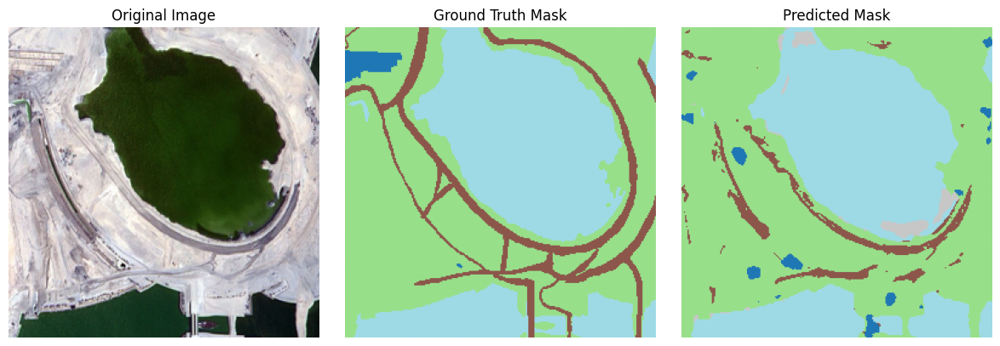

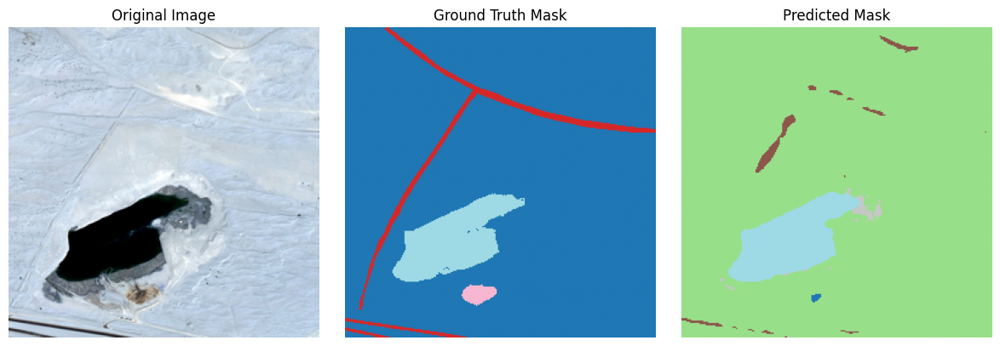

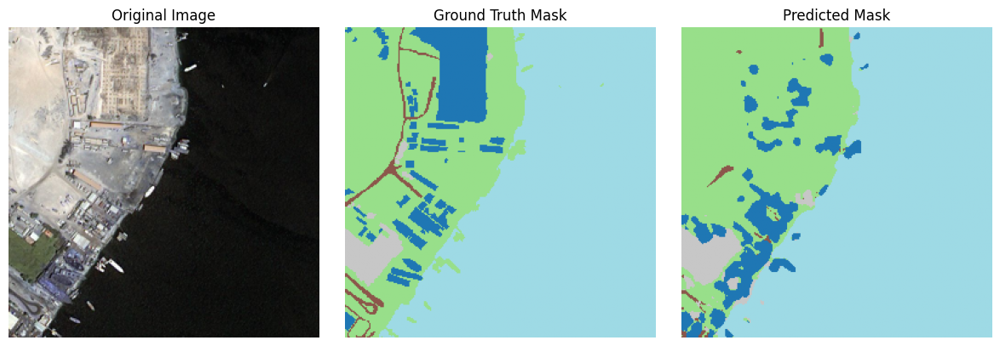

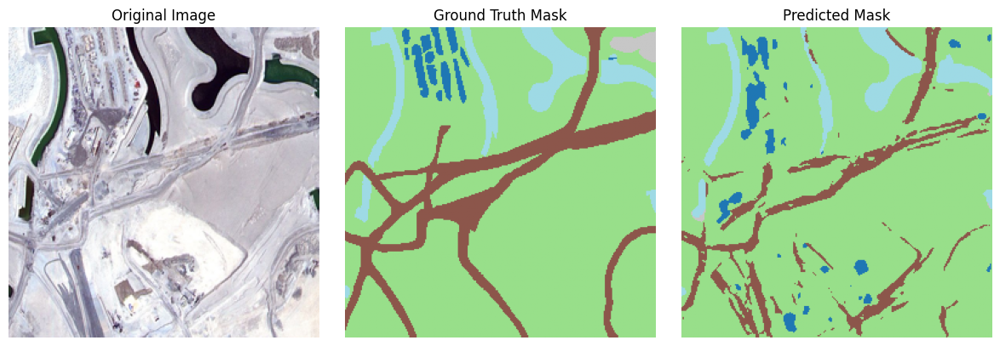

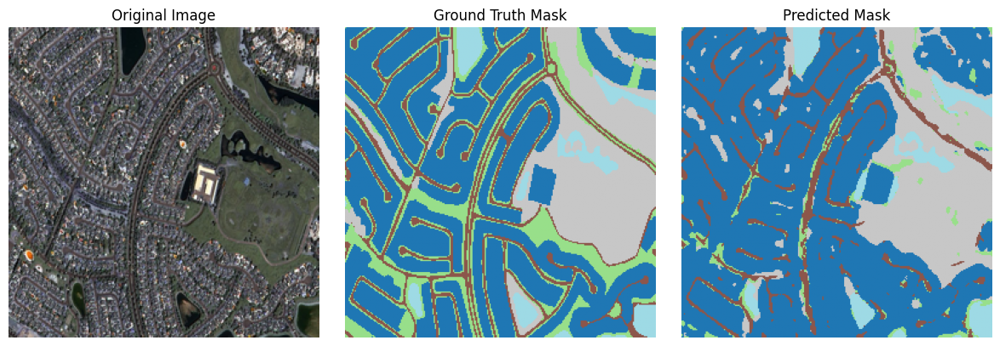

...

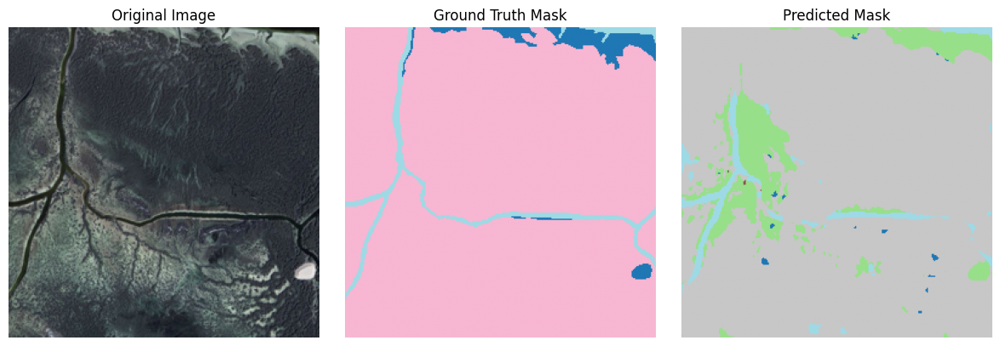

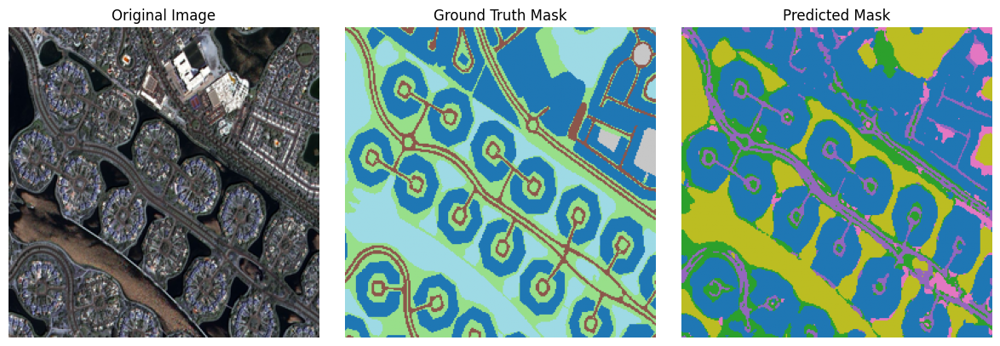

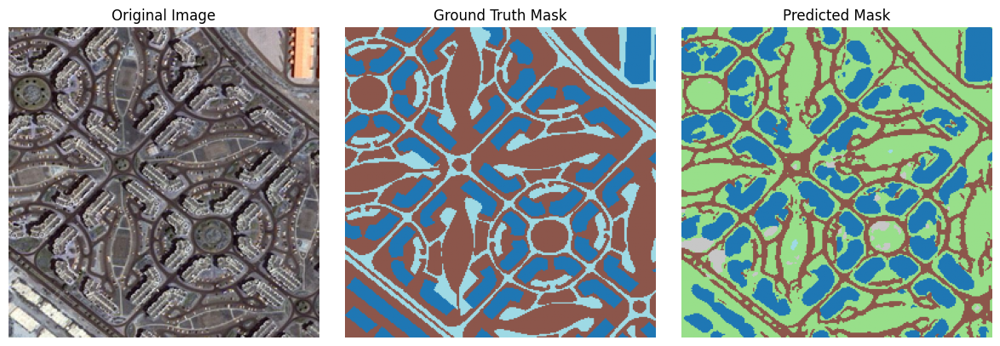

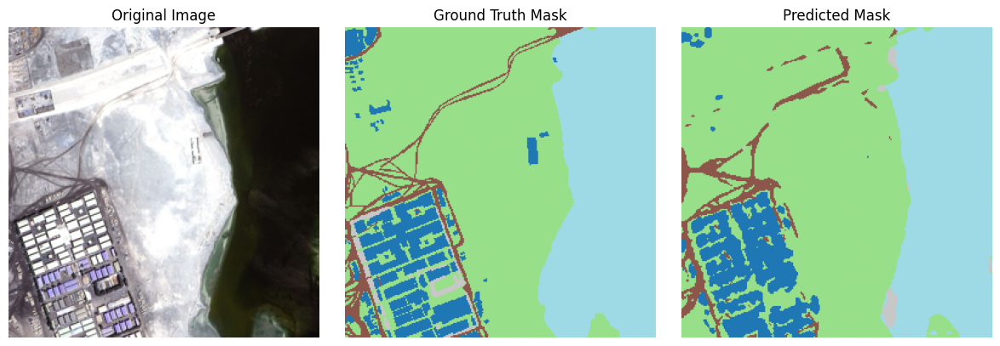

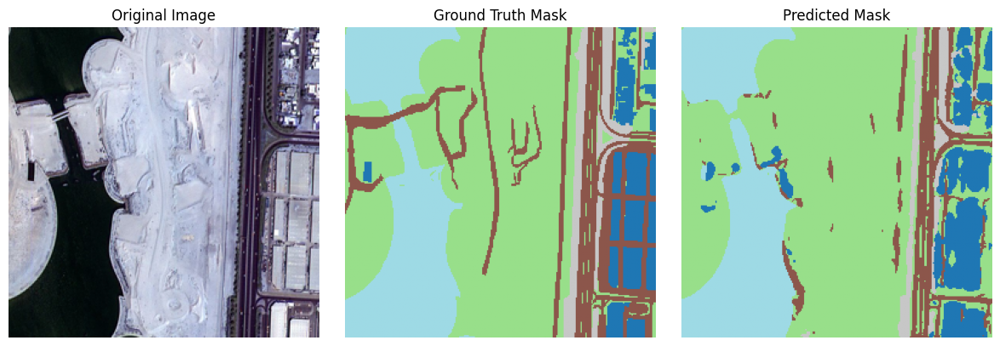

In [46]:
import matplotlib.pyplot as plt
import numpy as np

# Predict the masks
preds = ensemble_model.predict(X_val)

# Convert one-hot encoded masks to class labels (shape: (H, W))
y_true_classes = np.argmax(y_val, axis=-1)
y_pred_classes = np.argmax(preds, axis=-1)

# Loop through all validation samples
for i in range(len(X_val)):
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    # Original image
    axes[0].imshow(X_val[i])
    axes[0].set_title("Original Image")
    axes[0].axis('off')

    # Ground truth mask
    axes[1].imshow(y_true_classes[i], cmap='tab20')  # Using 'tab20' for distinct class colors
    axes[1].set_title("Ground Truth Mask")
    axes[1].axis('off')

    # Predicted mask
    axes[2].imshow(y_pred_classes[i], cmap='tab20')
    axes[2].set_title("Predicted Mask")
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

In [48]:
def compute_metrics_per_class(y_true, y_pred, num_classes=6):
    ious = []
    dices = []

    for class_id in range(num_classes):
        true_class = (y_true == class_id)
        pred_class = (y_pred == class_id)

        intersection = np.logical_and(true_class, pred_class).sum()
        union = np.logical_or(true_class, pred_class).sum()
        iou = intersection / union if union != 0 else 0
        ious.append(iou)

        dice = (2. * intersection) / (true_class.sum() + pred_class.sum()) if (true_class.sum() + pred_class.sum()) != 0 else 0
        dices.append(dice)

    return ious, dices

In [49]:
ious_all = np.zeros(6)
dices_all = np.zeros(6)
n_samples = len(X_val)

for i in range(n_samples):
    pred = ensemble_model.predict(np.expand_dims(X_val[i], axis=0))[0]
    pred_class = np.argmax(pred, axis=-1)
    true_class = np.argmax(y_val[i], axis=-1)

    ious, dices = compute_metrics_per_class(true_class, pred_class)
    ious_all += ious
    dices_all += dices

# Moyennes
ious_avg = ious_all / n_samples
dices_avg = dices_all / n_samples

1/1 ━━━━━━━━━━━━━━━━━━━━ 26s 26s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step


In [50]:
print("all dice mean is :",dices_avg)
print("all iou mean is :",ious_avg)

all dice mean is : [0.51092989 0.74594153 0.50031664 0.3750192  0.77460961 0.        ]
all iou mean is : [0.41003995 0.63962867 0.36872871 0.30880127 0.71697534 0.        ]


In [51]:
classes = ['Building', 'Land', 'Road', 'Vegetation', 'Water', 'Unlabeled']

print("Performance metrics per class:")
for i, class_name in enumerate(classes):
    print(f"{class_name}: IoU = {ious_avg[i]:.4f}, Dice Score = {dices_avg[i]:.4f}")

Performance metrics per class:
Building: IoU = 0.4100, Dice Score = 0.5109
Land: IoU = 0.6396, Dice Score = 0.7459
Road: IoU = 0.3687, Dice Score = 0.5003
Vegetation: IoU = 0.3088, Dice Score = 0.3750
Water: IoU = 0.7170, Dice Score = 0.7746
Unlabeled: IoU = 0.0000, Dice Score = 0.0000
